# Temporal probes

Label-free probes (no verification trials) of how much the stage-1 Conformers (see `src/README.md`'s "Temporal study") depend on frame order, on VoxCeleb1-O utterances:

- **Permutation sensitivity**: mean cosine distance between each utterance's OS embedding and its embedding with the order of `b`-frame blocks shuffled (`BS{b}`, `SS` for b = 1), as a function of the signal a block spans, `(b − 1) · 10 + 64` ms. Where the curve reaches 0 marks the time scale beyond which order no longer matters. The order-invariant model C stays at 0 throughout.
- **Join discontinuity** (no model): the distance between the two frames at every join of `BS{b}`, `GO{b}` and `GS{b}`, against consecutive frames of natural speech. It checks the SST bracket's assumption that `GO{b}` and `GS{b}` have equally rough joins (see `src/README.md`'s "Quality checks"): if GS's joins are clearly rougher than GO's at some b (GS / GO well above 1), the join artefacts don't fully cancel in L(b) there.
- **Attention distance**: attention-weighted mean |query − key| distance in ms per layer and head, on OS and SS input. Its distribution over offset, against uniform attention (dashed), shows whether a head mixes near and far keys or spreads evenly.

Needs the best checkpoints kept by the stage-1 runs (`training.keep_checkpoints`).

In [1]:
!module load uv && uv pip compile ../pyproject.toml -o ../requirements.txt
!source $HOME/dev/cluster_user/py_mgmt_3_venv_gpu_detect/gpu-detect.sh && pip install -r ../requirements.txt --index-url "$PYTORCH_INDEX_URL" --extra-index-url https://pypi.org/simple

Resolved 104 packages in 326ms                                       
# This file was autogenerated by uv via the following command:
#    uv pip compile ../pyproject.toml -o ../requirements.txt
annotated-doc==0.0.5
    # via typer
annotated-types==0.8.0
    # via pydantic
anyio==4.15.1
    # via
    #   cwevals
    #   httpx
    #   httpx2
certifi==2026.10.19
    # via
    #   httpcore
    #   httpx
    #   requests
cffi==2.1.1
    # via soundfile
charset-normalizer==3.5.2
    # via requests
click==8.5.0
    # via
    #   huggingface-hub
    #   wandb
cloudpickle==3.1.2
    # via joblib
contourpy==1.4.0
    # via matplotlib
cuda-bindings==13.4.4
    # via torch
cuda-pathfinder==1.8.3
    # via cuda-bindings
cuda-toolkit==13.0.3.0
    # via torch
cwevals==0.0.1b1
    # via wandb
cycler==0.12.1
    # via matplotlib
distro==1.9.0
    # via cwevals
filelock==4.2.4
    # via
    #   huggingface-hub
    #   torch
fonttools==4.67.0
    # via matplotlib
fsspec==2026.9.0
    # via
    #   huggi

In [ ]:
!source ../slurm/stage-voxceleb.submit

In [ ]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

ROOT = Path.cwd().parent  # notebook runs from doc/
sys.path.insert(0, str(ROOT))

from src.config import ExperimentConfig
from src.data.lazy_features import resolve_features
from src.data.voxceleb import VoxCelebCorpus
from src.evaluation.temporal_probes import (
    attention_distances,
    attention_offset_profiles,
    join_discontinuity,
    permutation_sensitivity,
)
from src.experiment import _checkpoint_path, _lazy_trial_utterances
from src.models.registry import build_model
from src.training.trainer import best_checkpoint_path

stage_dir = f"/scratch/{os.environ['SLURM_JOB_ID']}"
os.environ["VOXCELEB_ROOT"] = f"{stage_dir}/voxceleb1"
os.environ["VOXCELEB2_ROOT"] = f"{stage_dir}/voxceleb2"

In [3]:
models = {  # label -> (config the checkpoint was trained with, train strategy)
    "A (OS)": ("configs/conformer-voxceleb-stage1.yaml", "OS"),
    "B (RANDBS)": ("configs/conformer-voxceleb-stage1.yaml", "RANDBS"),
    "C (invariant)": ("configs/conformer-voxceleb-stage1-invariant.yaml", "OS"),
}
block_sizes = [1, 8, 16, 32, 64]  # SS, BS8, BS16, BS32, BS64
run_idx = 0
num_utterances = 1000      # VoxCeleb1-O utterances to probe
device = "cuda" if torch.cuda.is_available() else "cpu"

In [4]:
def load(config_path, train_strategy):
    config = ExperimentConfig.from_yaml(ROOT / config_path)
    config.training.checkpoint_dir = str(ROOT / config.training.checkpoint_dir)
    model = build_model(config)
    checkpoint = torch.load(best_checkpoint_path(_checkpoint_path(config, train_strategy, run_idx)), map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    return config, model.to(device).eval()


loaded = {label: load(*entry) for label, entry in models.items()}
config = next(iter(loaded.values()))[0]
transformation = config.transformation
corpus = VoxCelebCorpus(config)
utterances = _lazy_trial_utterances(corpus, corpus.dev_trial_pairs, transformation)[:num_utterances]
segment_length = config.data.segment_length(transformation)

==> VoxCeleb1: 153516 utterances (cached index /scratch/155204/voxceleb1/.sst-wav-index.tsv)
==> VoxCeleb2: 1092009 utterances (cached index /scratch/155204/voxceleb2/.sst-wav-index.tsv)


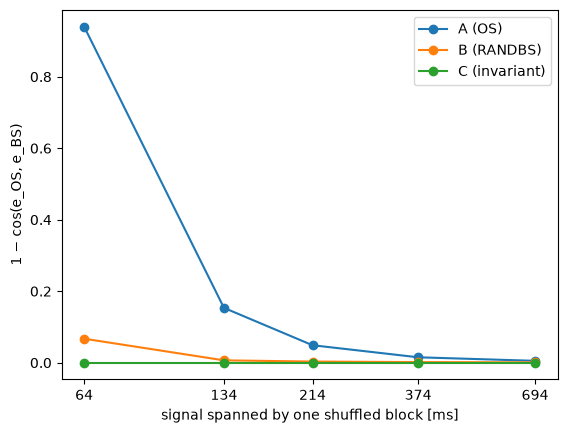

In [5]:
strategies = ["SS" if b == 1 else f"BS{b}" for b in block_sizes]
block_ms = [(b - 1) * transformation.frame_step_s * 1000 + transformation.frame_length_s * 1000 for b in block_sizes]

fig, ax = plt.subplots()
for label, (_, model) in loaded.items():
    sensitivity = permutation_sensitivity(model, utterances, segment_length, strategies, device)
    ax.plot(block_ms, [sensitivity[s] for s in strategies], "o-", label=label)
ax.set(xlabel="signal spanned by one shuffled block [ms]", ylabel="1 − cos(e_OS, e_BS)", xscale="log")
ax.set_xticks(block_ms, [f"{ms:.0f}" for ms in block_ms])
ax.minorticks_off()
ax.legend()
plt.show()

In [ ]:
join_block_sizes = [8, 16, 32, 64]
join_strategies = [f"{prefix}{b}" for b in join_block_sizes for prefix in ("BS", "GO", "GS")]
joins = join_discontinuity(utterances, segment_length, join_strategies)

adjacent = np.median(joins["adjacent"])
print(f"adjacent frames: median distance {adjacent:.2f}")
for b in join_block_sizes:
    medians = {prefix: np.median(joins[f"{prefix}{b}"]) for prefix in ("BS", "GO", "GS")}
    print(f"b={b:>2}: median join distance BS {medians['BS']:.2f}, GO {medians['GO']:.2f}, GS {medians['GS']:.2f}"
          f"  (GS / GO = {medians['GS'] / medians['GO']:.3f})")

fig, axes = plt.subplots(1, len(join_block_sizes), figsize=(4 * len(join_block_sizes), 3), sharex=True, sharey=True)
bins = np.linspace(0, np.quantile(np.concatenate(list(joins.values())), 0.99), 60)
for ax, b in zip(axes, join_block_sizes):
    for prefix in ("BS", "GO", "GS"):
        ax.hist(joins[f"{prefix}{b}"], bins=bins, density=True, histtype="step", label=prefix)
    ax.axvline(adjacent, color="k", linestyle="--", label="adjacent (median)")
    ax.set(title=f"b = {b}", xlabel="distance between the frames at a join")
axes[0].set_ylabel("density")
axes[-1].legend()
fig.tight_layout()
plt.show()

In [6]:
rng = np.random.default_rng(0)
segments = np.stack([resolve_features(features)[:segment_length] for features, _ in utterances[:200]])
shuffled = segments.copy()
for segment in shuffled:
    rng.shuffle(segment)

for label, (config, model) in loaded.items():
    step_ms = transformation.frame_step_s * 1000 * config.conformer.subsampling_time_stride ** 2
    for name, batch in (("OS", segments), ("SS", shuffled)):
        distances = attention_distances(model, torch.from_numpy(batch).float().unsqueeze(1).to(device), step_ms)
        print(f"{label:<14} {name}: mean attention distance [ms] per layer x head\n{np.round(distances).astype(int)}")

A (OS)         OS: mean attention distance [ms] per layer x head
[[576 534 505 583]
 [554 583 616 585]
 [634 638 683 667]
 [667 663 612 670]]
A (OS)         SS: mean attention distance [ms] per layer x head
[[650 611 582 598]
 [618 634 619 658]
 [651 628 703 678]
 [707 710 644 648]]
B (RANDBS)     OS: mean attention distance [ms] per layer x head
[[540 492 508 567]
 [639 557 603 559]
 [671 648 629 628]
 [639 639 653 649]]
B (RANDBS)     SS: mean attention distance [ms] per layer x head
[[608 608 612 625]
 [633 610 628 601]
 [665 638 628 634]
 [644 629 654 642]]
C (invariant)  OS: mean attention distance [ms] per layer x head
[[437 447 213 491]
 [627 646 564 590]
 [640 629 625 635]
 [639 631 637 634]]
C (invariant)  SS: mean attention distance [ms] per layer x head
[[608 603 555 615]
 [627 629 621 623]
 [628 628 627 628]
 [626 628 627 626]]


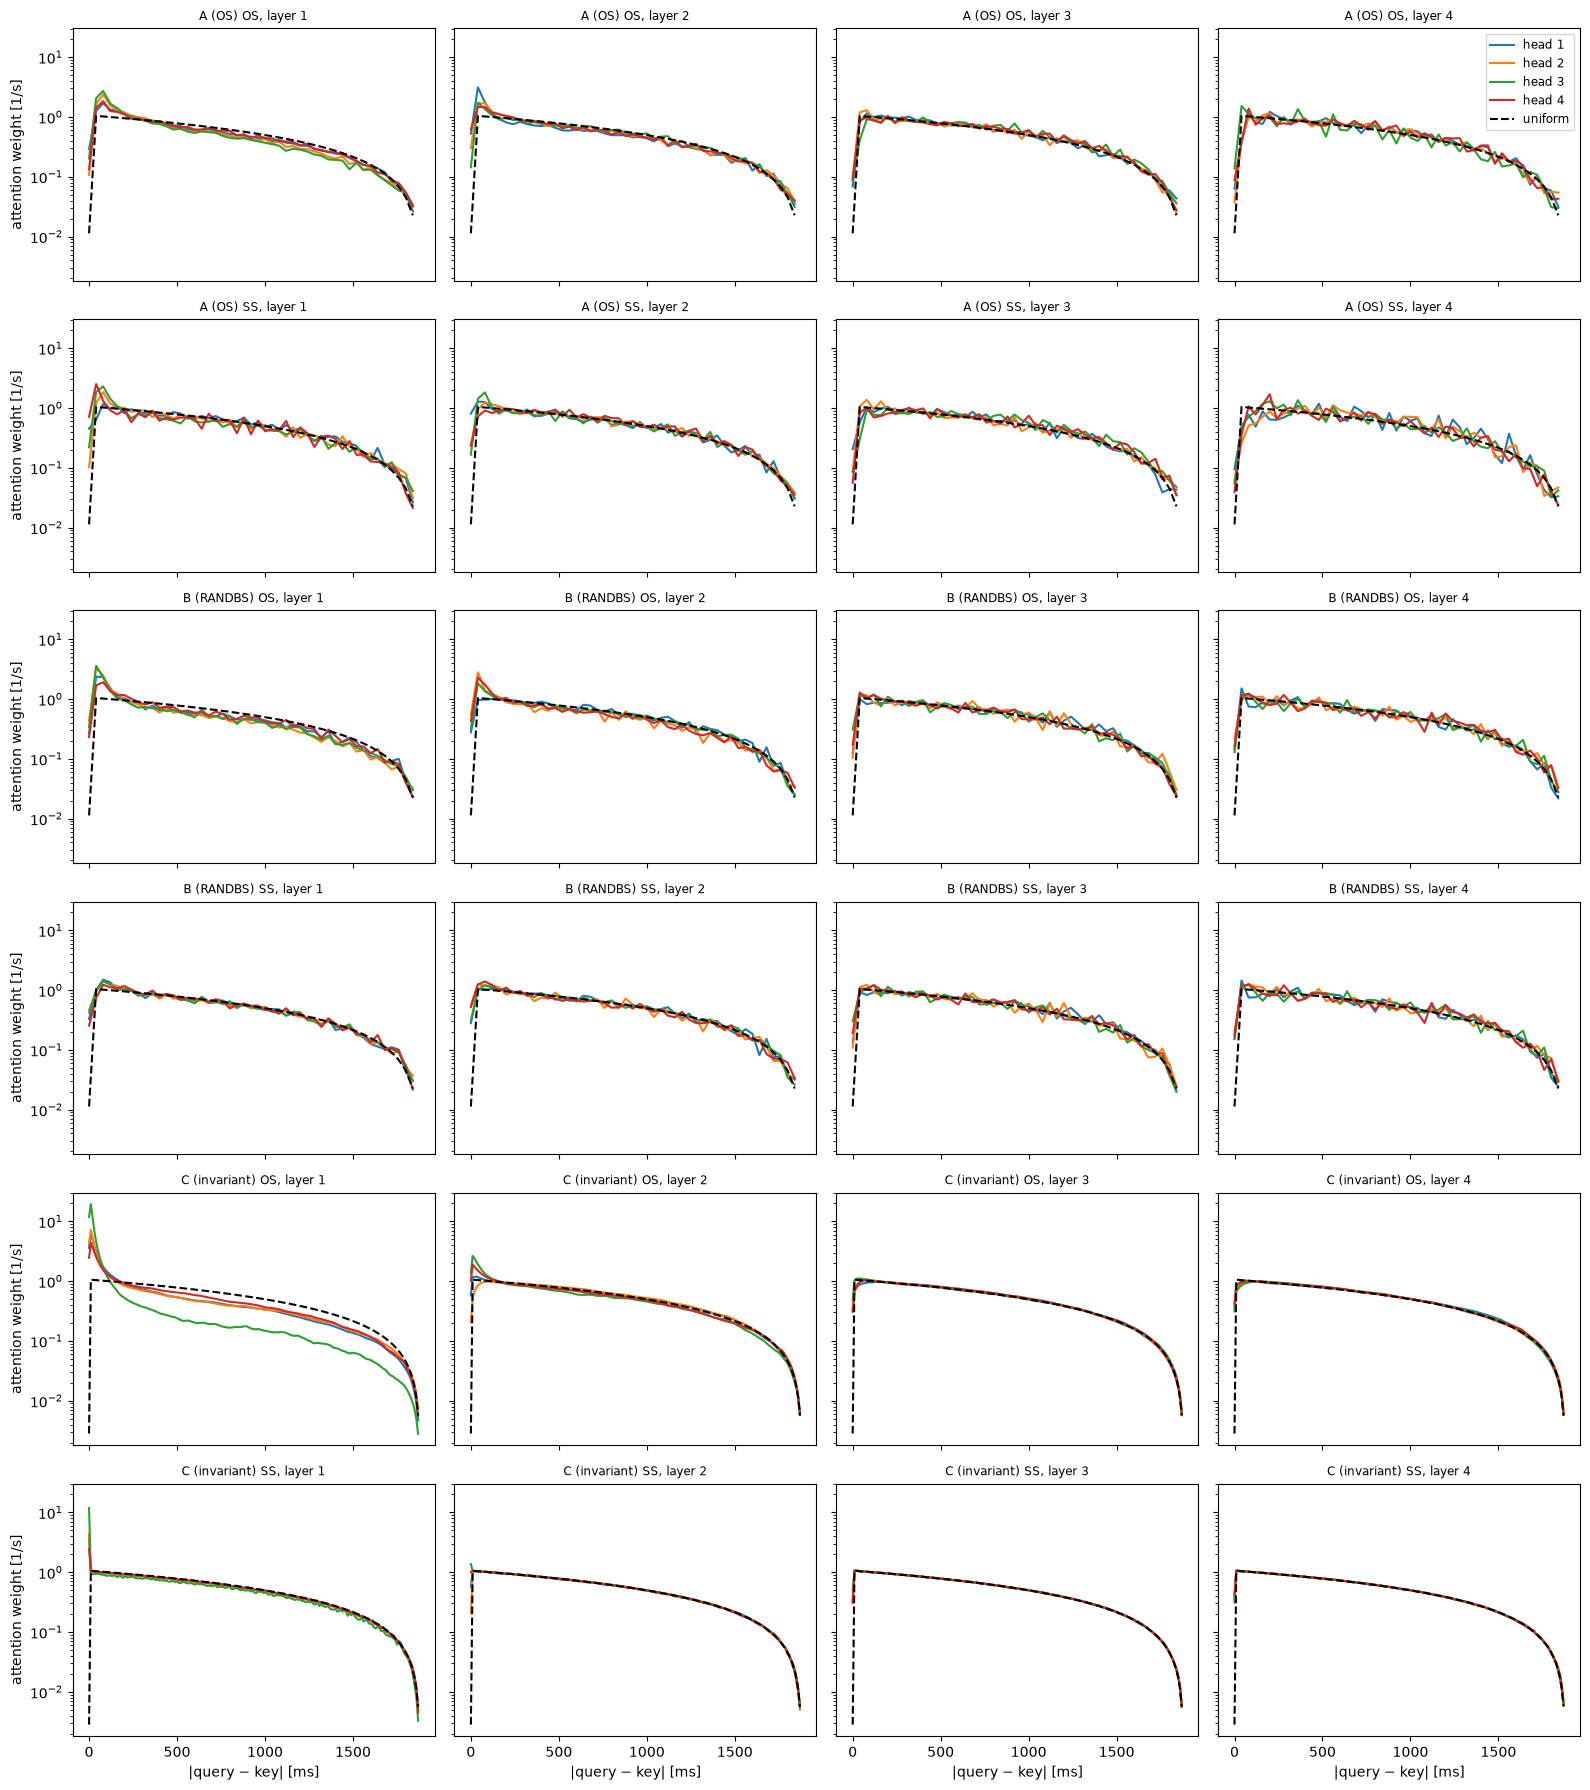

In [7]:
num_layers = config.conformer.num_layers
fig, axes = plt.subplots(2 * len(loaded), num_layers, figsize=(4 * num_layers, 3 * 2 * len(loaded)), sharex=True, sharey=True, squeeze=False)
for row, (label, (model_config, model)) in enumerate(loaded.items()):
    step_s = transformation.frame_step_s * model_config.conformer.subsampling_time_stride ** 2
    for i, (name, batch) in enumerate((("OS", segments), ("SS", shuffled))):
        profiles = attention_offset_profiles(model, torch.from_numpy(batch).float().unsqueeze(1).to(device))
        steps = profiles.shape[-1]
        offset = np.arange(steps)
        uniform = np.where(offset == 0, 1, 2 * (steps - offset)) / steps**2
        for layer, ax in enumerate(axes[2 * row + i]):
            for head, profile in enumerate(profiles[layer]):
                ax.plot(offset * step_s * 1000, profile / step_s, label=f"head {head + 1}")
            ax.plot(offset * step_s * 1000, uniform / step_s, "k--", label="uniform")
            ax.set_title(f"{label} {name}, layer {layer + 1}", fontsize="small")
for ax in axes[-1]:
    ax.set_xlabel("|query − key| [ms]")
for ax in axes[:, 0]:
    ax.set_ylabel("attention weight [1/s]")
axes[0, 0].set_yscale("log")
axes[0, -1].legend(fontsize="small")
fig.tight_layout()
plt.show()